# COU 07506 Digital Signal Processing Week 02: Sampling, Aliasing and Quantization 

* **Name:** Ismail Mbarouk Said
* **Class:** BEng24COE-4
* **Group:** 1
* **Registration No.:** 240242438521
* **Date:** 2026-11-25
* **Instructor checkpoints signed:** [ ] 1  

Task 2.1 — Aliasing of a sinusoid 

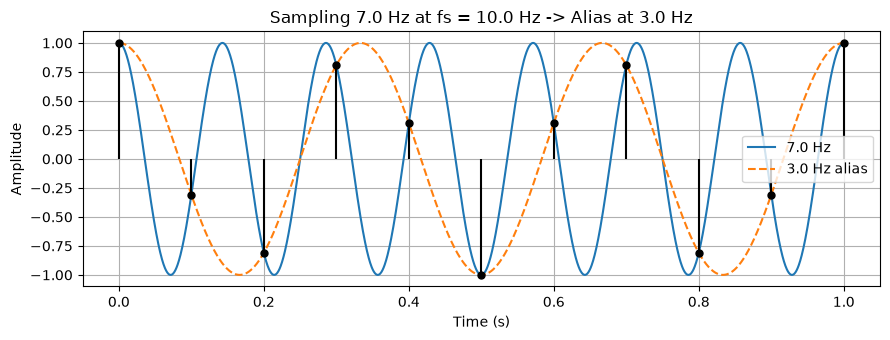

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio

plt.rcParams["figure.figsize"] = (9, 3.5)

# Task 2.1: Aliasing of a sinusoid
f0, fs = 7.0, 10.0
t = np.linspace(0, 1, 2000)
n = np.arange(0, int(fs) + 1)
tn = n / fs
f_alias = abs(f0 - fs * round(f0 / fs))

plt.plot(t, np.cos(2 * np.pi * f0 * t), label=f"{f0} Hz")
plt.plot(t, np.cos(2 * np.pi * f_alias * t), "--", label=f"{f_alias} Hz alias")
markerline, stemlines, baseline = plt.stem(tn, np.cos(2 * np.pi * f0 * tn), linefmt="k-", markerfmt="ko", basefmt=" ")
plt.setp(markerline, markersize=5)
plt.title(f"Sampling {f0} Hz at fs = {fs} Hz -> Alias at {f_alias} Hz")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

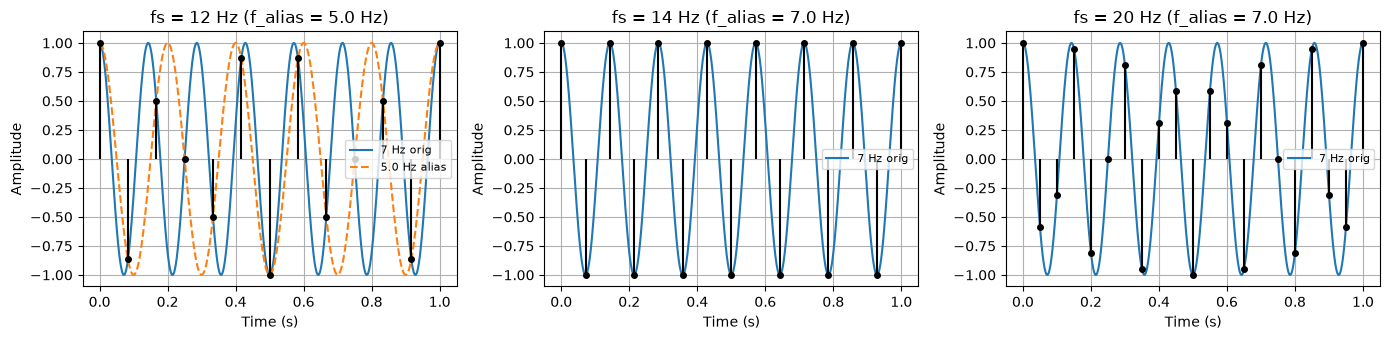

In [2]:
f0 = 7.0
t = np.linspace(0, 1, 2000)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

for ax, fs in zip(axes, [12.0, 14.0, 20.0]):
    n = np.arange(0, int(fs) + 1)
    tn = n / fs
    
    # Hesabu ya alias frequency kwa kutumia folding ndani ya [0, fs/2]
    f_alias = abs(f0 - fs * round(f0 / fs))
    
    ax.plot(t, np.cos(2 * np.pi * f0 * t), label=f"{f0:.0f} Hz orig")
    if f0 > fs / 2:
        ax.plot(t, np.cos(2 * np.pi * f_alias * t), "--", label=f"{f_alias:.1f} Hz alias")
    
    markerline, stemlines, baseline = ax.stem(
        tn, np.cos(2 * np.pi * f0 * tn), linefmt="k-", markerfmt="ko", basefmt=" "
    )
    plt.setp(markerline, markersize=4)
    ax.set_title(f"fs = {fs:.0f} Hz (f_alias = {f_alias:.1f} Hz)")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude")
    ax.legend(fontsize=8)
    ax.grid(True)

plt.tight_layout()
plt.show()

### Task 2.1 Comparison: $|F - k f_s|$ vs. Observed Alias Frequency ($F = 7\text{ Hz}$)

- For **$f_s = 12\text{ Hz}$** ($f_s/2 = 6\text{ Hz}$): Since $7\text{ Hz} > 6\text{ Hz}$, aliasing occurs. Using $k = 1$, $|F - k f_s| = |7 - 12| = 5\text{ Hz}$, so the sampled sinusoid appears at **$5\text{ Hz}$**.
- For **$f_s = 14\text{ Hz}$** ($f_s/2 = 7\text{ Hz}$): The signal frequency equals the Nyquist frequency ($F = f_s/2$). Using $|F - k f_s|$ with $k=1$ gives $7\text{ Hz}$, while in practice sampling right at the Nyquist limit makes frequency estimation sensitive to sampling phase (and can yield zero or attenuated amplitude depending on phase alignment).
- For **$f_s = 20\text{ Hz}$** ($f_s/2 = 10\text{ Hz}$): Since $7\text{ Hz} < 10\text{ Hz}$ (above Nyquist), there is **no aliasing** ($k = 0$, $|7 - 0| = 7\text{ Hz}$), and the reconstructed cosine matches the original $7\text{ Hz}$ tone.

Task 2.2 — Hear aliasing 

In [3]:
import os

# Task 2.2: Hear aliasing
fname = "my_voice_clean.wav"
if os.path.exists(fname):
    fs_audio, x_audio = wavfile.read(fname)
    x_audio = x_audio.mean(axis=1) if x_audio.ndim > 1 else x_audio.astype(float)
    x_audio = x_audio / np.max(np.abs(x_audio))
else:
    fs_audio = 44100
    t_chirp = np.arange(0, 3, 1 / fs_audio)
    x_audio = 0.5 * signal.chirp(t_chirp, 200, 3, 15000)

print(f"Source audio: fs = {fs_audio} Hz, samples = {len(x_audio)}")

for k in [2, 4, 8]:
    naive = x_audio[::k]
    proper = signal.decimate(x_audio, k, ftype="fir")
    new_fs = fs_audio // k
    print(f"\nk = {k} -> new fs = {new_fs} Hz (Nyquist = {new_fs / 2} Hz)")
    display(Audio(naive, rate=new_fs))
    display(Audio(proper, rate=new_fs))

Source audio: fs = 44100 Hz, samples = 170496

k = 2 -> new fs = 22050 Hz (Nyquist = 11025.0 Hz)



k = 4 -> new fs = 11025 Hz (Nyquist = 5512.5 Hz)



k = 8 -> new fs = 5512 Hz (Nyquist = 2756.0 Hz)


### Task 2.2 Listening Observations (k = 8)

- **Naive decimation (`x[::8]`):** Because high-frequency speech and background components above ~2.76 kHz are not filtered out before downsampling, they fold back into the audible band as harsh, metallic, or robotic aliasing artifacts/distortion.
- **Filtered decimation (`signal.decimate(..., ftype="fir")`):** The built-in FIR low-pass anti-aliasing filter removes frequencies above the new Nyquist limit before dropping samples, producing a smoother/cleaner (though lower-bandwidth/muffled) speech signal without harsh aliasing fold-over.

Task 2.3 — A uniform quantizer

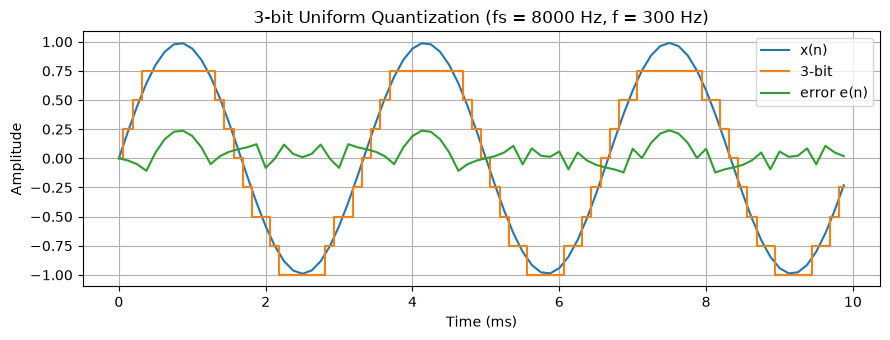

In [4]:
# Task 2.3: A uniform quantizer
def quantize(x, bits, full_scale=1.0):
    delta = 2.0 * full_scale / (2 ** bits)
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1 / fs)
x = 0.99 * np.sin(2 * np.pi * 300 * t)
xq = quantize(x, 3)
err = x - xq

plt.figure(figsize=(9, 3.5))
plt.plot(t * 1e3, x, label="x(n)")
plt.step(t * 1e3, xq, where="mid", label="3-bit")
plt.plot(t * 1e3, err, label="error e(n)")
plt.title("3-bit Uniform Quantization (fs = 8000 Hz, f = 300 Hz)")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Task 2.4 — Verify the 6 dB-per-bit rule 

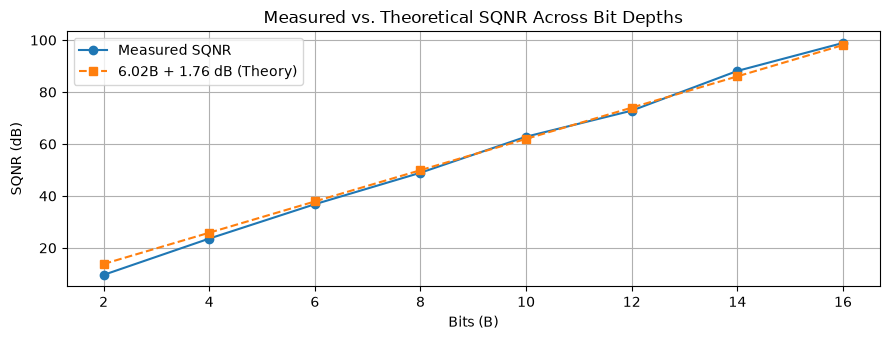

B =  2 bits -> Measured:   9.60 dB | Theoretical:  13.80 dB
B =  4 bits -> Measured:  23.58 dB | Theoretical:  25.84 dB
B =  6 bits -> Measured:  36.81 dB | Theoretical:  37.88 dB
B =  8 bits -> Measured:  48.93 dB | Theoretical:  49.92 dB
B = 10 bits -> Measured:  62.81 dB | Theoretical:  61.96 dB
B = 12 bits -> Measured:  72.84 dB | Theoretical:  74.00 dB
B = 14 bits -> Measured:  88.13 dB | Theoretical:  86.04 dB
B = 16 bits -> Measured:  98.91 dB | Theoretical:  98.08 dB


In [5]:
# Task 2.4: Verify the 6 dB-per-bit rule
bits = np.arange(2, 17, 2)
meas = [
    10 * np.log10(np.sum(x ** 2) / np.sum((x - quantize(x, B)) ** 2))
    for B in bits
]
theo = 6.02 * bits + 1.76

plt.figure(figsize=(9, 3.5))
plt.plot(bits, meas, "o-", label="Measured SQNR")
plt.plot(bits, theo, "s--", label="6.02B + 1.76 dB (Theory)")
plt.title("Measured vs. Theoretical SQNR Across Bit Depths")
plt.xlabel("Bits (B)")
plt.ylabel("SQNR (dB)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

for b, m, th in zip(bits, meas, theo):
    print(f"B = {b:2d} bits -> Measured: {m:6.2f} dB | Theoretical: {th:6.2f} dB")

Task 2.5 — Quantize your voice

In [6]:
# Task 2.5: Quantize your voice
if "x_audio" not in globals() or "fs_audio" not in globals():
    fname = "my_voice_clean.wav"
    if os.path.exists(fname):
        fs_audio, x_audio = wavfile.read(fname)
        x_audio = x_audio.mean(axis=1) if x_audio.ndim > 1 else x_audio.astype(float)
        x_audio = x_audio / np.max(np.abs(x_audio))
    else:
        fs_audio = 44100
        t_fallback = np.arange(0, 3, 1 / fs_audio)
        x_audio = 0.5 * signal.chirp(t_fallback, 200, 3, 15000)

# Hakikisha sauti ipo ndani ya [-1, 1]
x_speech = x_audio / np.max(np.abs(x_audio))

for b in [4, 8, 12]:
    xq_speech = quantize(x_speech, b, full_scale=1.0)
    err_speech = x_speech - xq_speech
    sqnr_speech = 10 * np.log10(np.sum(x_speech ** 2) / np.sum(err_speech ** 2))
    sqnr_sine_theory = 6.02 * b + 1.76
    print(
        f"Bits = {b:2d} | Speech SQNR = {sqnr_speech:6.2f} dB "
        f"| Full-scale sine theory = {sqnr_sine_theory:6.2f} dB"
    )
    display(Audio(xq_speech, rate=fs_audio))

Bits =  4 | Speech SQNR =   9.89 dB | Full-scale sine theory =  25.84 dB


Bits =  8 | Speech SQNR =  31.73 dB | Full-scale sine theory =  49.92 dB


Bits = 12 | Speech SQNR =  55.77 dB | Full-scale sine theory =  74.00 dB


## Pre-lab Questions (Week 2)

- **(a) Alias frequency for a 7 kHz tone sampled at 10 kHz:**  
  With $f_s = 10\text{ kHz}$, the Nyquist frequency is $f_s / 2 = 5\text{ kHz}$. Since $F = 7\text{ kHz} > 5\text{ kHz}$, aliasing occurs at:
  $$F_{\text{alias}} = |F - k f_s| = |7 - 1(10)| = 3\text{ kHz}$$

- **(b) Step size $\Delta$ and theoretical SQNR for an 8-bit quantizer over $\pm 1\text{ V}$ ($X_m = 1\text{ V}$, $B = 8$):**  
  $$\Delta = \frac{2 X_m}{2^B} = \frac{2(1)}{2^8} = \frac{2}{256} \approx 0.0078125\text{ V}\ (7.81\text{ mV})$$
  $$\text{SQNR}_{\text{theory}} \approx 6.02(8) + 1.76 = 48.16 + 1.76 = 49.92\text{ dB}$$

### Task 2.5 Discussion: Speech Quantization vs. Full-Scale Sine Wave

- **Auditory observations (4, 8, and 12 bits):** At 4 bits, quantization noise is clearly audible as gritty/background distortion; at 8 bits, speech intelligibility is high with only faint noise during quieter segments; at 12 bits, the quantized speech sounds clean and close to the original.
- **Why measured speech SQNR is lower:** A full-scale sine wave maintains a high, steady RMS level close to the quantizer's maximum range, maximizing signal power $\sum x^2$ relative to quantization error power $\sum e^2$. Speech signals have pauses, consonants, and varying amplitude dynamics, resulting in a lower average signal power $\sum x^2$ for the same quantization step size $\Delta$, and hence a lower measured SQNR than a full-scale sine wave of the same bit depth.

## Analysis Questions (Week 2)

1. **Why a 7 Hz tone sampled at $f_s = 10\text{ Hz}$ appears at 3 Hz:**  
   When sampling at $f_s = 10\text{ Hz}$, the baseband (first Nyquist zone) spans $0\text{ Hz}$ to $5\text{ Hz}$, with spectral replicas centered around multiples of $f_s$ ($\pm 10\text{ Hz}, \pm 20\text{ Hz}, \dots$). A component at $+7\text{ Hz}$ lies above the Nyquist limit ($5\text{ Hz}$) and is closer to the replica centered at $10\text{ Hz}$ (specifically its negative image at $-7\text{ Hz}$ shifted by $+10\text{ Hz}$, giving $|7 - 10| = 3\text{ Hz}$). On a frequency axis from $0$ to $10\text{ Hz}$, the $7\text{ Hz}$ peak folds across $5\text{ Hz}$ into $3\text{ Hz}$ (and its mirror image at $10 - 3 = 7\text{ Hz}$).

2. **Why aliasing in the naïve version (Task 2.2) cannot be removed afterwards:**  
   Once high-frequency energy above the new Nyquist limit folds into lower frequencies during unfiltered downsampling (`x[::k]`), those aliased components overlap directly with valid lower-frequency components in the same frequency bins. No post-sampling filter can separate the folded alias energy from true signal energy at the same frequency without also removing the true signal.

3. **SQNR change per added bit and agreement with measurement:**  
   Increasing bit depth by $1\text{ bit}$ halves the step size $\Delta$ (reducing quantization error variance $\Delta^2 / 12$ by a factor of $4$, or $6.02\text{ dB}$), so theoretical SQNR increases by approximately **$6.02\text{ dB}$ per bit** (about $12.04\text{ dB}$ per 2-bit step). The measured SQNR curve in Task 2.4 follows this roughly $6\text{ dB/bit}$ slope across the tested bit depths, with minor deviations at very high bit counts where signal/error characteristics behave slightly differently from ideal white uniform noise assumptions.

4. **Sampling rate and bit depth for a $0\text{--}100\,^\circ\text{C}$ sensor ($\le 0.1\,^\circ\text{C/s}$ max rate of change, $0.01\,^\circ\text{C}$ resolution):**  
   - **Resolution / Bit depth:** Over a $100\,^\circ\text{C}$ span, a step size $\Delta \le 0.01\,^\circ\text{C}$ requires at least $\frac{100}{0.01} = 10{,}000$ quantization levels. Since $2^{13} = 8{,}192 < 10{,}000$ and $2^{14} = 16{,}384 \ge 10{,}000$, at least **14 bits** (with $\Delta = 100 / 16384 \approx 0.0061\,^\circ\text{C} < 0.01\,^\circ\text{C}$; **16 bits** is also a practical standard choice for comfortable margin).
   - **Sampling rate:** Even if the signal changed at $0.1\,^\circ\text{C/s}$, a sampling rate of **$f_s = 1\text{ Hz}$** (1 sample per second, or e.g. $2\text{--}5\text{ Hz}$ if anti-aliasing/oversampling margin is desired) is more than sufficient for such a slow physical temperature process—at $1\text{ Hz}$, the maximum change between consecutive samples is at most $0.1\,^\circ\text{C}$, and any high-frequency electrical noise above $0.5\text{ Hz}$ should be attenuated by an analog low-pass anti-aliasing filter before sampling.